# Spam Message Detection Using LSTM

## Project Overview
This project uses Natural Language Processing (NLP) and a Long Short-Term Memory (LSTM) neural network to classify SMS messages as spam or legitimate (ham).

## Objectives
- Analyze and preprocess SMS messages.
- Convert text into numerical sequences using tokenization.
- Train an LSTM model to classify messages.
- Evaluate the model using accuracy, precision, recall, and F1-score.
- Test the model on new SMS messages.

In [1]:
print("Spam Message Detection Using LSTM")
print("Project setup started successfully!")

Spam Message Detection Using LSTM
Project setup started successfully!


In [2]:
import sys

print("Python version:", sys.version)

Python version: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]


In [3]:
packages = ["pandas", "numpy", "matplotlib", "sklearn", "tensorflow"]

for package in packages:
    try:
        module = __import__(package)
        print(f"{package}: installed")
    except ImportError:
        print(f"{package}: not installed")

pandas: installed
numpy: installed
matplotlib: installed
sklearn: installed
tensorflow: not installed


## 1. Dataset Collection and Loading

In [4]:
import urllib.request
import zipfile
from pathlib import Path
import pandas as pd

# Create the data folder
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

# Official UCI dataset URL
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# Download the dataset
zip_path = data_dir / "sms_spam_collection.zip"

if not zip_path.exists():
    print("Downloading SMS Spam Collection dataset...")
    urllib.request.urlretrieve(url, zip_path)
    print("Download completed!")
else:
    print("Dataset ZIP already exists.")

# Extract the SMS data file
data_path = data_dir / "SMSSpamCollection"

if not data_path.exists():
    with zipfile.ZipFile(zip_path, "r") as zip_file:
        data_path.write_bytes(
            zip_file.read("SMSSpamCollection")
        )
    print("Dataset extracted successfully!")
else:
    print("Dataset file already exists.")

# Load the dataset into a DataFrame
df = pd.read_csv(
    data_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Download completed!
Dataset extracted successfully!

Dataset loaded successfully!
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Exploratory Data Analysis (EDA)

In this section, we analyze the SMS dataset to understand its
structure, identify missing values, and visualize the distribution
of spam and ham messages.

In [5]:
# Display dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate messages
print("\nDuplicate Messages:")
print(df.duplicated().sum())

# Count spam and ham messages
print("\nMessage Distribution:")
print(df["label"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing Values:
label      0
message    0
dtype: int64

Duplicate Messages:
403

Message Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


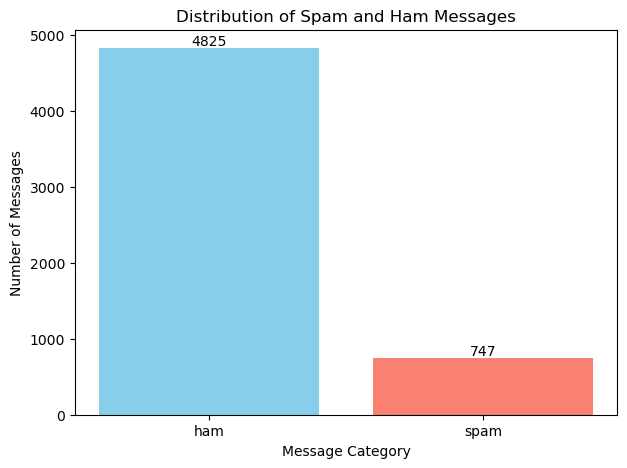

In [6]:
import matplotlib.pyplot as plt

# Count spam and ham messages
message_counts = df["label"].value_counts()

# Create bar chart
plt.figure(figsize=(7, 5))

plt.bar(
    message_counts.index,
    message_counts.values,
    color=["skyblue", "salmon"]
)

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

# Display count above each bar
for i, count in enumerate(message_counts.values):
    plt.text(i, count + 30, str(count), ha="center")

plt.show()

## 3. Data Preprocessing

In this section, we remove duplicate messages, encode the target labels,
and split the dataset into training and testing sets. These steps prepare
the SMS messages for tokenization and LSTM model training.

In [7]:
# Check dataset size before removing duplicates
print("Before removing duplicates:", df.shape)

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Check dataset size after removing duplicates
print("After removing duplicates:", df.shape)

# Verify duplicates have been removed
print("Remaining duplicates:", df.duplicated().sum())

# Check the new label distribution
print("\nUpdated message distribution:")
print(df["label"].value_counts())

Before removing duplicates: (5572, 2)
After removing duplicates: (5169, 2)
Remaining duplicates: 0

Updated message distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


In [8]:
# Convert text labels into numerical labels
df["label_encoded"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print(df[["label", "label_encoded", "message"]].head())
print("\nEncoded label counts:")
print(df["label_encoded"].value_counts())

  label  label_encoded                                            message
0   ham              0  Go until jurong point, crazy.. Available only ...
1   ham              0                      Ok lar... Joking wif u oni...
2  spam              1  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham              0  U dun say so early hor... U c already then say...
4   ham              0  Nah I don't think he goes to usf, he lives aro...

Encoded label counts:
label_encoded
0    4516
1     653
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split

X = df["message"].astype(str)
y = df["label_encoded"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training messages: 4135
Testing messages: 1034

Training label distribution:
label_encoded
0    3613
1     522
Name: count, dtype: int64

Testing label distribution:
label_encoded
0    903
1    131
Name: count, dtype: int64


## 4. Text Tokenization and Padding

Text messages are converted into numerical sequences using a tokenizer.
Padding is applied to make all sequences the same length so they can be
processed by the LSTM neural network.

In [11]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [12]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("TensorFlow is ready for LSTM training!")

TensorFlow version: 2.21.0
TensorFlow is ready for LSTM training!


In [13]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Parameters
vocab_size = 5000
max_length = 100
oov_token = "<OOV>"

# Create and fit tokenizer on training messages only
tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token=oov_token
)
tokenizer.fit_on_texts(X_train)

# Convert messages into numerical sequences
X_train_sequences = tokenizer.texts_to_sequences(X_train)
X_test_sequences = tokenizer.texts_to_sequences(X_test)

# Make all sequences the same length
X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training data shape:", X_train_padded.shape)
print("Testing data shape:", X_test_padded.shape)
print("\nExample message:")
print(X_train.iloc[0])
print("\nNumerical sequence:")
print(X_train_sequences[0][:20])

Training data shape: (4135, 100)
Testing data shape: (1034, 100)

Example message:
Ta-Daaaaa! I am home babe, are you still up ?

Numerical sequence:
[1160, 3541, 2, 63, 77, 155, 22, 3, 79, 42]


## 5. Building the LSTM Deep Learning Model

We use an Embedding layer to learn word representations, an LSTM layer
to capture sequential patterns in messages, and a Dense output layer
to classify each SMS as spam or ham.

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Build the LSTM model
model = Sequential([
    Embedding(
        input_dim=5000,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.5),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.build(input_shape=(None, max_length))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 100, 64)             │         320,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 355,137 (1.35 MB)

 Trainable params: 355,137 (1.35 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Train the LSTM model
history = model.fit(
    X_train_padded,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 131ms/step - accuracy: 0.9081 - loss: 0.3096 - val_accuracy: 0.9807 - val_loss: 0.0709
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 19s 117ms/step - accuracy: 0.9909 - loss: 0.0488 - val_accuracy: 0.9867 - val_loss: 0.0486
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 20s 115ms/step - accuracy: 0.9949 - loss: 0.0219 - val_accuracy: 0.9831 - val_loss: 0.0565
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 21s 116ms/step - accuracy: 0.9979 - loss: 0.0084 - val_accuracy: 0.9915 - val_loss: 0.0543


## 6. Model Evaluation

The trained LSTM model is evaluated on the held-out test dataset.
We use accuracy, precision, recall, F1-score, and a confusion matrix
to understand how effectively the model identifies spam messages.

In [16]:
# Evaluate the model on unseen test messages
test_loss, test_accuracy = model.evaluate(
    X_test_padded,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

Test Loss: 0.0856
Test Accuracy: 0.9768
Test Accuracy (%): 97.68%


Classification Report:

              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       903
        Spam       0.98      0.83      0.90       131

    accuracy                           0.98      1034
   macro avg       0.98      0.91      0.94      1034
weighted avg       0.98      0.98      0.98      1034



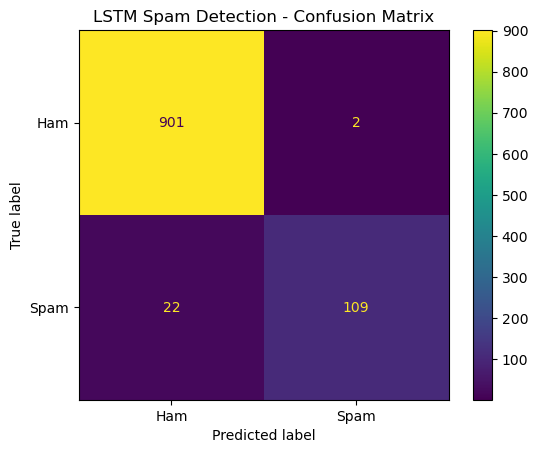

In [17]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict spam probabilities
y_prob = model.predict(X_test_padded, verbose=0).ravel()

# Convert probabilities to class labels
y_pred = (y_prob >= 0.5).astype(int)

# Display classification metrics
print("Classification Report:\n")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display.plot()
plt.title("LSTM Spam Detection - Confusion Matrix")
plt.show()

## 7. Testing with Custom SMS Messages

The trained LSTM model is tested on new messages that were not part
of the training or testing dataset.

In [18]:
def predict_message(message):
    # Convert the message into a numerical sequence
    sequence = tokenizer.texts_to_sequences([message])

    # Pad it using the same settings as training
    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    # Predict spam probability
    probability = float(model.predict(padded, verbose=0)[0][0])

    # Classify the message
    prediction = "SPAM" if probability >= 0.5 else "HAM"

    print("Message:", message)
    print("Prediction:", prediction)
    print(f"Spam probability: {probability:.2%}")


# Try sample messages
predict_message("Congratulations! You have won a free prize. Claim now!")
print()
predict_message("Hey, are we meeting at the library tomorrow?")

Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
Spam probability: 97.91%

Message: Hey, are we meeting at the library tomorrow?
Prediction: HAM
Spam probability: 0.01%


## 8. Saving the Trained Model and Tokenizer

In [19]:
from pathlib import Path
import json

# Create the models folder
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

# Save the trained model
model.save(models_dir / "spam_lstm.keras")

# Save the tokenizer
tokenizer_json = tokenizer.to_json()

with open(
    models_dir / "tokenizer.json",
    "w",
    encoding="utf-8"
) as file:
    file.write(tokenizer_json)

# Save configuration for future predictions
config = {
    "vocab_size": vocab_size,
    "max_length": max_length,
    "threshold": 0.5
}

with open(
    models_dir / "config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(config, file, indent=4)

print("Model, tokenizer, and configuration saved successfully!")
print("Files:", [file.name for file in models_dir.iterdir()])

Model, tokenizer, and configuration saved successfully!
Files: ['config.json', 'spam_lstm.keras', 'tokenizer.json']
